# AquaGuard · Machine Learning
## Vai cair chuva forte amanhã em São Paulo?

**CitizenTech:** AquaGuard — prevenção de alagamentos em bairros vulneráveis de São Paulo (ex.: Jardim Pantanal).
**Integrantes:** Guilherme Cezarino Simoes · Fabrini Soares

### Pergunta de ML
> Com as condições meteorológicas observadas **hoje** pela estação oficial do INMET, conseguimos prever se **amanhã** haverá
> **chuva forte (≥ 20 mm no dia)** — o volume a partir do qual alagamentos passam a ser frequentes em São Paulo?

Tipo de problema: **classificação binária** (amanhã: chuva forte = 1 / não = 0).
Por que importa: um aviso com ~24 h de antecedência dá tempo de o morador tirar o carro da rua baixa, suspender pertences e
planejar o trajeto — algo que o sensor IoT (que mede a água *já subindo*) não oferece sozinho.

### Dados reais e públicos
| Item | Valor |
|---|---|
| Fonte | INMET — Banco de Dados Meteorológicos, dados históricos horários |
| Link | https://portal.inmet.gov.br/dadoshistoricos |
| Estação | **A701 — São Paulo / Mirante de Santana** (lat −23,48; lon −46,62) |
| Período | 01/01/2012 a 31/12/2025 (14 anos, ~122 mil registros horários) |
| Download | `dados/download_inmet.py` (reprodutível) |


In [1]:
import glob, io, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
LIMIAR_CHUVA_FORTE_MM = 20.0
FIG = pathlib.Path("figuras"); FIG.mkdir(exist_ok=True)

## 1. Carga dos dados brutos
Os arquivos do INMET mudaram de formato ao longo dos anos (data `2012-01-01` × `2025/01/01`, hora `00:00` × `0000 UTC`). Lemos por **posição de coluna** e normalizamos. O valor `-9999` significa *sem medição* e vira `NaN`.

In [2]:
COLS = ["data", "hora", "precip", "pressao", "pressao_max", "pressao_min", "radiacao", "temp", "orvalho",
        "temp_max", "temp_min", "orvalho_max", "orvalho_min", "umid_max", "umid_min", "umid", "vento_dir",
        "rajada", "vento"]

def ler_inmet(caminho):
    df = pd.read_csv(caminho, sep=";", skiprows=8, encoding="latin-1", decimal=",", header=0,
                     usecols=range(19), names=COLS, na_values=["-9999", ""], dtype=str)
    for c in COLS[2:]:
        df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")
    df.loc[df["precip"] < -1000, "precip"] = np.nan
    data = pd.to_datetime(df["data"].str.replace("/", "-", regex=False), format="%Y-%m-%d")
    hora = df["hora"].str.extract(r"(\d{2}):?(\d{2})")[0].astype(int)
    df["datahora_utc"] = data + pd.to_timedelta(hora, unit="h")
    return df.drop(columns=["data", "hora"])

arquivos = sorted(glob.glob("dados/raw/INMET_A701_*.csv"))
horario = pd.concat([ler_inmet(a) for a in arquivos], ignore_index=True)
horario = horario.replace(-9999, np.nan).sort_values("datahora_utc").reset_index(drop=True)
print(f"{len(arquivos)} arquivos | {len(horario):,} registros horários | "
      f"{horario.datahora_utc.min():%d/%m/%Y} a {horario.datahora_utc.max():%d/%m/%Y}")
horario.head()

14 arquivos | 122,736 registros horários | 01/01/2012 a 31/12/2025


,precip,pressao,pressao_max,pressao_min,radiacao,temp,orvalho,temp_max,temp_min,orvalho_max,orvalho_min,umid_max,umid_min,umid,vento_dir,rajada,vento,datahora_utc
0,0.6,921.1,921.1,921.0,NaN,19.6,19.5,19.7,19.6,19.6,19.4,99.0,99.0,99.0,100.0,3.4,1.7,2012-01-01 00:00:00
1,1.0,920.9,921.1,920.9,NaN,19.6,19.3,19.7,19.5,19.6,19.3,99.0,98.0,98.0,100.0,3.8,1.7,2012-01-01 01:00:00
2,1.4,920.2,920.9,920.2,NaN,19.4,19.3,19.6,19.4,19.4,19.2,99.0,98.0,99.0,101.0,4.0,1.0,2012-01-01 02:00:00
3,0.2,919.2,920.2,919.2,NaN,19.4,19.2,19.5,19.4,19.4,19.2,99.0,99.0,99.0,91.0,2.2,0.2,2012-01-01 03:00:00
4,0.2,918.5,919.2,918.5,NaN,19.5,19.4,19.5,19.3,19.4,19.2,99.0,99.0,99.0,7.0,1.3,0.0,2012-01-01 04:00:00


In [3]:
falt = horario.isna().mean().sort_values(ascending=False).mul(100).round(1)
print("% de valores ausentes por variável (horário):"); falt.to_frame("% NaN").T

% de valores ausentes por variável (horário):


,radiacao,precip,orvalho_min,orvalho_max,rajada,temp_max,umid_max,umid_min,temp_min,pressao_min,pressao_max,orvalho,vento_dir,vento,umid,temp,pressao,datahora_utc
% NaN,47.1,0.9,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.0


## 2. Preparação: de horário para diário
Convertemos UTC → horário de Brasília (UTC−3) e agregamos por **dia local**. Um dia só é usado se tiver **≥ 20 das 24 horas** de precipitação medida — evita rotular como "sem chuva" um dia em que a estação estava desligada.

In [4]:
h = horario.copy()
h["datahora_local"] = h["datahora_utc"] - pd.Timedelta(hours=3)
h["dia"] = h["datahora_local"].dt.floor("D")
g = h.groupby("dia")
diario = pd.DataFrame({
    "horas_validas": g["precip"].count(),
    "precip_total": g["precip"].sum(min_count=1),
    "precip_max_h": g["precip"].max(),
    "horas_chuva": g["precip"].apply(lambda s: (s > 0.2).sum()),
    "pressao_media": g["pressao"].mean(),
    "pressao_amplitude": g["pressao_max"].max() - g["pressao_min"].min(),
    "temp_max": g["temp_max"].max(),
    "temp_min": g["temp_min"].min(),
    "temp_media": g["temp"].mean(),
    "orvalho_medio": g["orvalho"].mean(),
    "umid_media": g["umid"].mean(),
    "umid_min": g["umid_min"].min(),
    "radiacao_total": g["radiacao"].sum(min_count=1),
    "vento_medio": g["vento"].mean(),
    "rajada_max": g["rajada"].max(),
})
diario = diario.asfreq("D")  # garante calendário contínuo (dias sem dado = NaN)
diario.loc[diario["horas_validas"] < 20, "precip_total"] = np.nan
print(f"Dias no calendário: {len(diario):,} | dias com precipitação válida: {diario.precip_total.notna().sum():,}")
diario.describe().T.round(2)

Dias no calendário: 5,115 | dias com precipitação válida: 5,056


,count,mean,std,min,25%,50%,75%,max
horas_validas,5115.0,23.77,2.01,0.00,24.00,24.00,24.00,24.00
precip_total,5056.0,4.24,10.64,0.00,0.00,0.00,2.40,142.40
precip_max_h,5088.0,2.24,5.77,0.00,0.00,0.00,1.20,82.00
horas_chuva,5115.0,1.26,2.56,0.00,0.00,0.00,1.00,21.00
pressao_media,5104.0,927.23,3.42,914.96,924.85,926.97,929.45,938.80
pressao_amplitude,5104.0,4.09,1.14,0.80,3.30,3.90,4.60,12.20
temp_max,5104.0,26.55,4.51,8.50,23.50,26.90,30.00,38.40
temp_min,5104.0,16.82,3.08,4.00,14.70,17.10,19.20,25.70
temp_media,5104.0,20.61,3.39,7.23,18.35,20.83,23.08,30.97
orvalho_medio,5104.0,14.01,3.36,-0.26,11.67,14.48,16.80,20.72


### Engenharia de atributos (somente informação disponível **até hoje**)
- Tendência: variação de pressão, temperatura e umidade em relação a ontem (frentes frias derrubam a pressão).
- Memória: chuva acumulada nos últimos 3 e 7 dias (solo encharcado).
- Sazonalidade: mês codificado em seno/cosseno (verão chuvoso).
- **Alvo:** `chuva_forte_amanha = precip_total(dia+1) ≥ 20 mm`.

In [5]:
d = diario.copy()
d["delta_pressao"] = d["pressao_media"].diff()
d["delta_temp_max"] = d["temp_max"].diff()
d["delta_umid"] = d["umid_media"].diff()
d["amplitude_termica"] = d["temp_max"] - d["temp_min"]
d["deficit_orvalho"] = d["temp_media"] - d["orvalho_medio"]
d["chuva_3d"] = d["precip_total"].rolling(3, min_periods=2).sum()
d["chuva_7d"] = d["precip_total"].rolling(7, min_periods=5).sum()
doy = d.index.dayofyear
d["sazon_sin"] = np.sin(2 * np.pi * doy / 365.25)
d["sazon_cos"] = np.cos(2 * np.pi * doy / 365.25)
d["precip_amanha"] = d["precip_total"].shift(-1)
d["alvo"] = (d["precip_amanha"] >= LIMIAR_CHUVA_FORTE_MM).astype("float")
d.loc[d["precip_amanha"].isna(), "alvo"] = np.nan

FEATURES = ["precip_total", "precip_max_h", "horas_chuva", "chuva_3d", "chuva_7d", "pressao_media",
            "delta_pressao", "pressao_amplitude", "temp_max", "temp_min", "amplitude_termica", "delta_temp_max",
            "umid_media", "umid_min", "delta_umid", "deficit_orvalho", "radiacao_total", "vento_medio",
            "rajada_max", "sazon_sin", "sazon_cos"]

base = d.dropna(subset=FEATURES + ["alvo"]).copy()
base["alvo"] = base["alvo"].astype(int)
print(f"Dias utilizáveis após limpeza: {len(base):,} de {len(d):,} ({len(base)/len(d):.1%})")
print(f"Dias com chuva forte no dia seguinte: {base.alvo.sum()} ({base.alvo.mean():.1%}) -> classes desbalanceadas")

Dias utilizáveis após limpeza: 5,008 de 5,115 (97.9%)
Dias com chuva forte no dia seguinte: 340 (6.8%) -> classes desbalanceadas


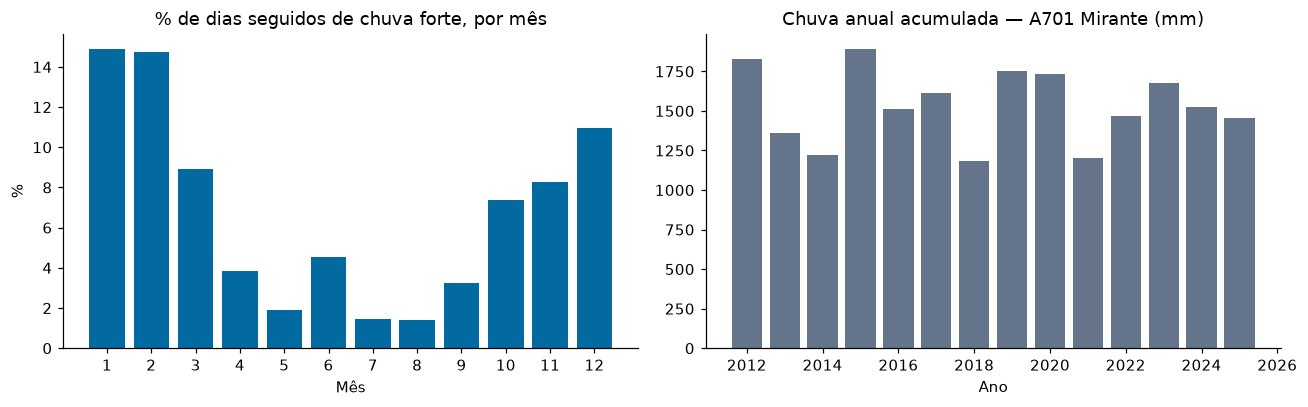

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
mensal = base.groupby(base.index.month)["alvo"].mean() * 100
ax[0].bar(mensal.index, mensal.values, color="#0369a1")
ax[0].set(title="% de dias seguidos de chuva forte, por mês", xlabel="Mês", ylabel="%", xticks=range(1, 13))
anual = d["precip_total"].resample("YE").sum(min_count=200)
ax[1].bar(anual.index.year, anual.values, color="#64748b")
ax[1].set(title="Chuva anual acumulada — A701 Mirante (mm)", xlabel="Ano")
plt.tight_layout(); plt.savefig(FIG / "01_eda_sazonalidade.png"); plt.show()

## 3. Divisão treino/teste (temporal)
Em séries temporais, embaralhar vaza o futuro para o treino. Usamos corte cronológico:
- **Treino:** 2012 → 2022
- **Teste:** 2023 → 2025 (nunca visto durante a escolha de hiperparâmetros)

In [7]:
treino = base[base.index < "2023-01-01"]
teste = base[base.index >= "2023-01-01"]
X_tr, y_tr = treino[FEATURES], treino["alvo"]
X_te, y_te = teste[FEATURES], teste["alvo"]
pd.DataFrame({
    "período": [f"{treino.index.min():%Y-%m-%d} a {treino.index.max():%Y-%m-%d}", f"{teste.index.min():%Y-%m-%d} a {teste.index.max():%Y-%m-%d}"],
    "dias": [len(treino), len(teste)],
    "positivos (chuva forte)": [int(y_tr.sum()), int(y_te.sum())],
    "% positivos": [f"{y_tr.mean():.1%}", f"{y_te.mean():.1%}"]}, index=["treino", "teste"])

,período,dias,positivos (chuva forte),% positivos
treino,2012-01-05 a 2022-12-31,3974,266,6.7%
teste,2023-01-01 a 2025-12-30,1034,74,7.2%


## 4. Modelo escolhido: Random Forest
**Justificativa**
- Dados **tabulares** com poucas milhares de linhas e relações **não lineares** (ex.: queda de pressão só importa no verão) — árvores capturam interações sem precisar normalizar.
- Robusto a outliers (tempestades extremas) e a atributos correlacionados (temp/orvalho/umidade).
- `class_weight="balanced"` trata o desbalanceamento (~8% de positivos) sem gerar dados sintéticos.
- Fornece **importância dos atributos**, o que permite explicar o alerta ao cidadão e à Defesa Civil.
- LSTM exigiria muito mais dados; KMeans é não supervisionado (não responde a pergunta); MLP perde interpretabilidade.

## 5. Treino com diferentes hiperparâmetros
**3 hiperparâmetros × 18 combinações**, validação cruzada **somente no treino** com `TimeSeriesSplit(5)` (cada dobra valida em anos posteriores aos de treino). Métrica: **PR-AUC (average precision)**, adequada a classes raras.

Critério de escolha: **regra de 1 desvio-padrão** — muitas combinações empatam na validação; entre as que ficam a até 1 desvio do melhor PR-AUC, ficamos com a de **menor gap treino-validação** (menos overfitting, mais estável para os próximos anos).

In [8]:
grade = {
    "n_estimators": [150, 400],
    "max_depth": [4, 8, None],
    "min_samples_leaf": [1, 10, 30],
}
cv = TimeSeriesSplit(n_splits=5)
rf = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)

def regra_um_desvio(cvr):
    """Regra de 1 desvio-padrão: entre as combinações cujo PR-AUC de validação está a até 1 desvio do melhor,
    escolhe a de MENOR gap treino-validação (modelo mais simples/menos sobreajustado)."""
    val, std, tr = (np.asarray(cvr[k]) for k in ("mean_test_pr_auc", "std_test_pr_auc", "mean_train_pr_auc"))
    melhor = int(np.argmax(val))
    candidatos = np.where(val >= val[melhor] - std[melhor])[0]
    return int(candidatos[np.argmin((tr - val)[candidatos])])

busca = GridSearchCV(rf, grade, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1"},
                     refit=regra_um_desvio, cv=cv, return_train_score=True, n_jobs=1)
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
tabela = res[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
              "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "mean_test_f1",
              "rank_test_pr_auc"]].copy()
tabela.columns = ["n_estimators", "max_depth", "min_samples_leaf", "PR-AUC treino(CV)", "PR-AUC validação(CV)",
                  "desvio val.", "ROC-AUC val.", "F1 val.", "rank"]
tabela["gap treino-val"] = tabela["PR-AUC treino(CV)"] - tabela["PR-AUC validação(CV)"]
tabela = tabela.sort_values("rank").round(3)
tabela.to_csv("resultados_grid_search.csv", index=False)
tabela["escolhido"] = np.where(tabela.index == busca.best_index_, "◀ escolhido", "")
print(f"Combinações testadas: {len(tabela)}  |  Escolhido (regra 1-DP): {busca.best_params_}")
tabela

Combinações testadas: 18  |  Escolhido (regra 1-DP): {'max_depth': 4, 'min_samples_leaf': 30, 'n_estimators': 150}


,n_estimators,max_depth,min_samples_leaf,PR-AUC treino(CV),PR-AUC validação(CV),desvio val.,ROC-AUC val.,F1 val.,rank,gap treino-val,escolhido
13,400,None,1,1.000,0.177,0.047,0.754,0.085,1,0.823,
12,150,None,1,1.000,0.177,0.050,0.755,0.107,2,0.823,
4,150,4,30,0.360,0.176,0.039,0.756,0.233,3,0.184,◀ escolhido
14,150,None,10,0.917,0.175,0.046,0.761,0.241,4,0.742,
15,400,None,10,0.924,0.175,0.046,0.760,0.251,5,0.749,
1,400,4,1,0.548,0.175,0.038,0.760,0.238,6,0.373,
5,400,4,30,0.364,0.174,0.038,0.757,0.235,7,0.190,
7,400,8,1,0.983,0.174,0.034,0.761,0.236,8,0.809,
0,150,4,1,0.536,0.174,0.039,0.759,0.244,9,0.362,
6,150,8,1,0.979,0.174,0.038,0.758,0.234,10,0.805,


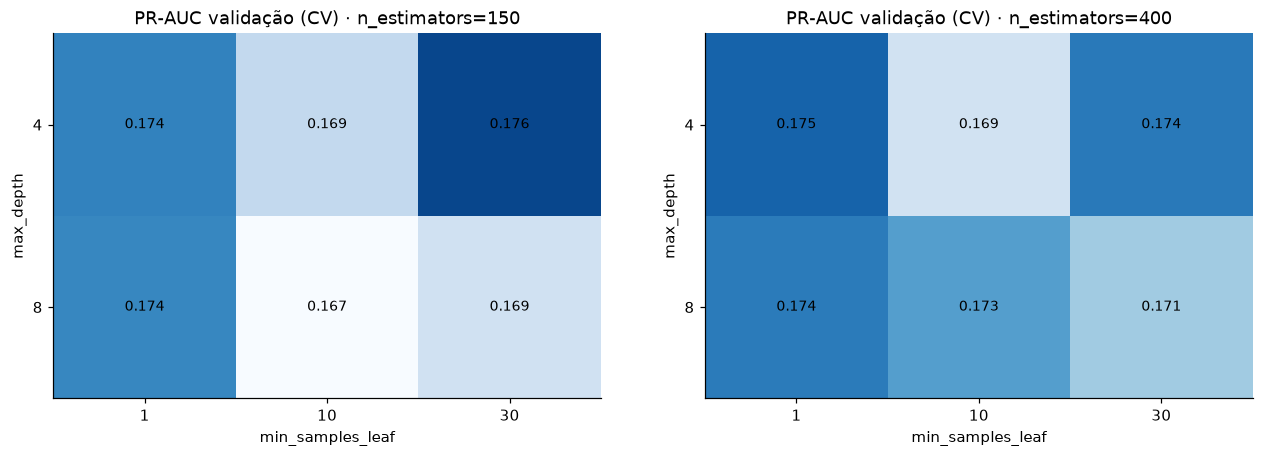

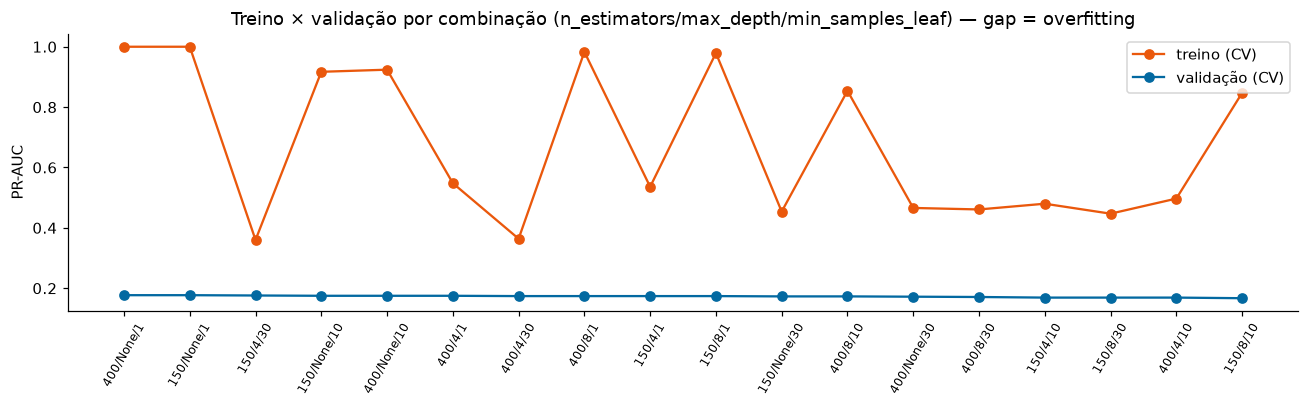

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, n in zip(axes, grade["n_estimators"]):
    sub = res[res.param_n_estimators == n]
    piv = sub.pivot_table(index=sub.param_max_depth.astype(str), columns="param_min_samples_leaf", values="mean_test_pr_auc")
    im = ax.imshow(piv.values, cmap="Blues", vmin=res.mean_test_pr_auc.min(), vmax=res.mean_test_pr_auc.max())
    ax.set(xticks=range(piv.shape[1]), xticklabels=piv.columns, yticks=range(piv.shape[0]), yticklabels=piv.index,
           xlabel="min_samples_leaf", ylabel="max_depth", title=f"PR-AUC validação (CV) · n_estimators={n}")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "02_grid_search_heatmap.png"); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.8))
idx = np.arange(len(tabela))
ax.plot(idx, tabela["PR-AUC treino(CV)"], "o-", label="treino (CV)", color="#ea580c")
ax.plot(idx, tabela["PR-AUC validação(CV)"], "o-", label="validação (CV)", color="#0369a1")
ax.set(xticks=idx, xticklabels=[f"{r.n_estimators}/{r.max_depth}/{r.min_samples_leaf}" for r in tabela.itertuples()],
       ylabel="PR-AUC", title="Treino × validação por combinação (n_estimators/max_depth/min_samples_leaf) — gap = overfitting")
plt.xticks(rotation=60, fontsize=8); ax.legend(); plt.tight_layout(); plt.savefig(FIG / "03_overfitting_por_combinacao.png"); plt.show()

### Escolha do limiar de decisão
A probabilidade padrão de 0,5 não é ideal com classes raras. Escolhemos o limiar que maximiza o **F1 nas previsões out-of-fold do treino** (sem tocar no teste).

In [10]:
from sklearn.base import clone
oof = np.full(len(y_tr), np.nan)
for tr_idx, va_idx in cv.split(X_tr):
    m = clone(busca.best_estimator_).fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
    oof[va_idx] = m.predict_proba(X_tr.iloc[va_idx])[:, 1]
mask = ~np.isnan(oof)
limiares = np.arange(0.10, 0.81, 0.02)
f1s = [f1_score(y_tr[mask], oof[mask] >= t) for t in limiares]
LIMIAR = float(limiares[int(np.argmax(f1s))])
print(f"Limiar escolhido (máx. F1 out-of-fold no treino): {LIMIAR:.2f}")

Limiar escolhido (máx. F1 out-of-fold no treino): 0.56


## 6. Resultados em treino e teste (lado a lado)

In [11]:
modelo = busca.best_estimator_
def metricas(y, p, limiar):
    pred = (p >= limiar).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Recall (chuvas fortes detectadas)": recall_score(y, pred), "Precisão (alertas corretos)": precision_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred), "Acurácia balanceada": balanced_accuracy_score(y, pred), "Brier": brier_score_loss(y, p)}

p_tr = modelo.predict_proba(X_tr)[:, 1]
p_te = modelo.predict_proba(X_te)[:, 1]
comp = pd.DataFrame({"Treino (ajuste completo)": metricas(y_tr, p_tr, LIMIAR),
                     "Treino (CV out-of-fold)": metricas(y_tr[mask], oof[mask], LIMIAR),
                     "Teste 2023-2025": metricas(y_te, p_te, LIMIAR)}).round(3)
base_rate = y_te.mean()
print(f"Referência: um classificador aleatório teria PR-AUC ≈ {base_rate:.3f} (taxa de positivos no teste)")
comp.to_csv("metricas_treino_teste.csv"); comp

Referência: um classificador aleatório teria PR-AUC ≈ 0.072 (taxa de positivos no teste)


,Treino (ajuste completo),Treino (CV out-of-fold),Teste 2023-2025
ROC-AUC,0.845,0.760,0.792
PR-AUC,0.286,0.164,0.208
Recall (chuvas fortes detectadas),0.786,0.600,0.689
Precisão (alertas corretos),0.191,0.159,0.179
F1,0.308,0.251,0.284
Acurácia balanceada,0.774,0.687,0.723
Brier,0.176,0.175,0.183


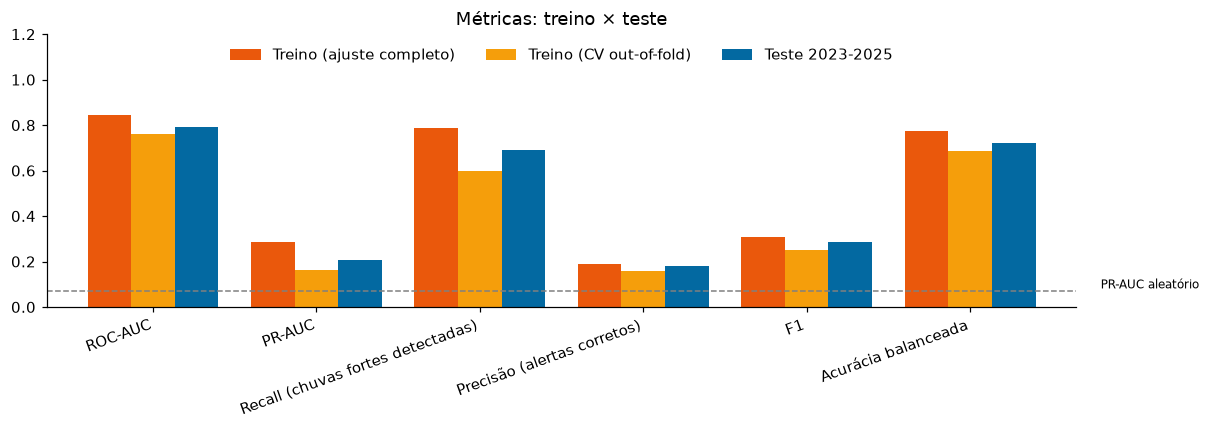

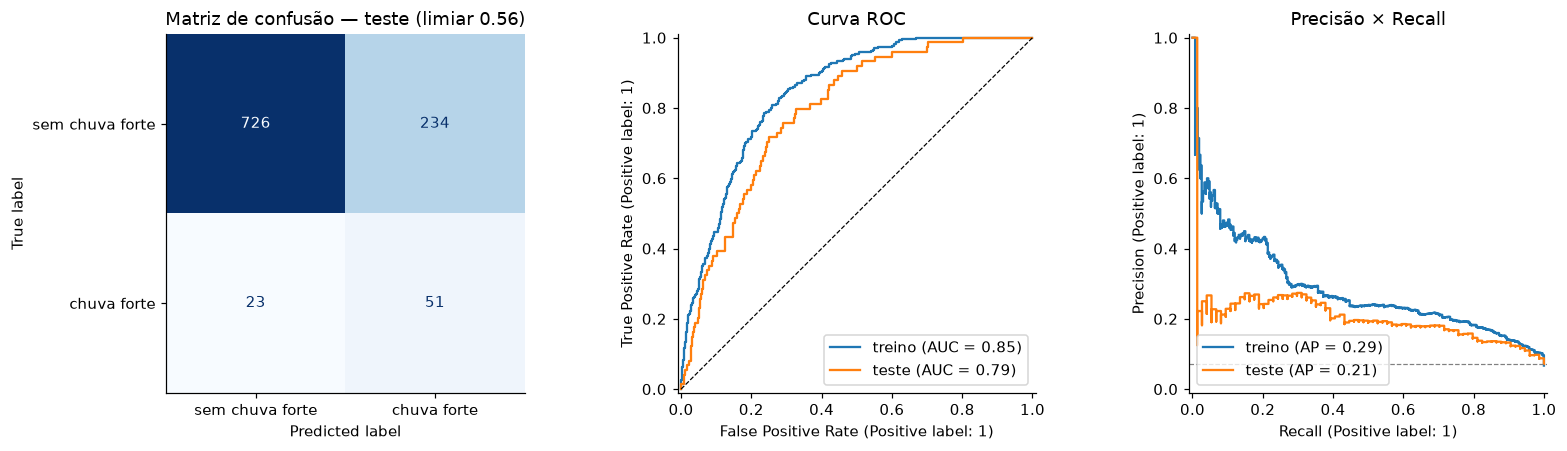

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
comp.drop(index="Brier").plot.bar(ax=ax, color=["#ea580c", "#f59e0b", "#0369a1"], width=0.8)
ax.axhline(base_rate, ls="--", c="gray", lw=1); ax.text(6.4, base_rate + 0.01, "PR-AUC aleatório", fontsize=8, ha="right")
ax.set(title="Métricas: treino × teste", ylim=(0, 1.2)); plt.xticks(rotation=20, ha="right")
ax.legend(loc="upper center", ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "04_metricas_treino_teste.png"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, p_te >= LIMIAR), display_labels=["sem chuva forte", "chuva forte"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Matriz de confusão — teste (limiar {LIMIAR:.2f})")
RocCurveDisplay.from_predictions(y_tr, p_tr, ax=ax[1], name="treino"); RocCurveDisplay.from_predictions(y_te, p_te, ax=ax[1], name="teste")
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_title("Curva ROC")
PrecisionRecallDisplay.from_predictions(y_tr, p_tr, ax=ax[2], name="treino"); PrecisionRecallDisplay.from_predictions(y_te, p_te, ax=ax[2], name="teste")
ax[2].axhline(base_rate, ls="--", c="gray", lw=.8); ax[2].set_title("Precisão × Recall")
plt.tight_layout(); plt.savefig(FIG / "05_confusao_roc_pr.png"); plt.show()

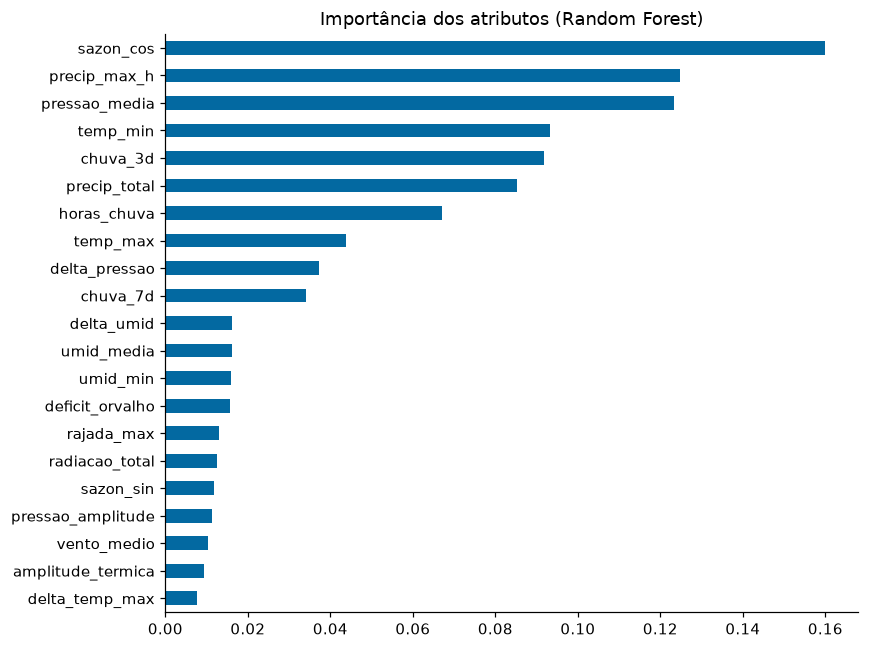

sazon_cos        0.160
precip_max_h     0.125
pressao_media    0.123
temp_min         0.093
chuva_3d         0.092
precip_total     0.085
horas_chuva      0.067
temp_max         0.044
dtype: float64

In [13]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
imp.plot.barh(ax=ax, color="#0369a1"); ax.set_title("Importância dos atributos (Random Forest)")
plt.tight_layout(); plt.savefig(FIG / "06_importancia_atributos.png"); plt.show()
imp.sort_values(ascending=False).head(8).round(3)

### Discussão de overfitting

In [14]:
gap_full = comp.loc["PR-AUC", "Treino (ajuste completo)"] - comp.loc["PR-AUC", "Teste 2023-2025"]
gap_cv = comp.loc["PR-AUC", "Treino (CV out-of-fold)"] - comp.loc["PR-AUC", "Teste 2023-2025"]
print(f"PR-AUC treino (ajuste completo) − teste: {gap_full:+.3f}")
print(f"PR-AUC treino (CV out-of-fold) − teste:  {gap_cv:+.3f}")
pior = tabela.sort_values("gap treino-val", ascending=False).iloc[0]
print(f"Combinação mais sobreajustada no grid: {int(pior.n_estimators)}/{pior.max_depth}/{int(pior.min_samples_leaf)} "
      f"(treino {pior['PR-AUC treino(CV)']:.3f} × validação {pior['PR-AUC validação(CV)']:.3f})")

PR-AUC treino (ajuste completo) − teste: +0.078
PR-AUC treino (CV out-of-fold) − teste:  -0.044
Combinação mais sobreajustada no grid: 400/None/1 (treino 1.000 × validação 0.177)


## 7. O que isso significa para o cidadão

In [15]:
cm = confusion_matrix(y_te, p_te >= LIMIAR); tn, fp, fn, tp = cm.ravel()
dias = len(y_te); anos = dias / 365.25
print(f"No período de teste ({dias} dias ≈ {anos:.1f} anos) houve {int(y_te.sum())} dias de chuva forte.")
print(f"• O modelo avisou na véspera em {tp} deles ({tp/(tp+fn):.0%}).")
print(f"• Deixou passar {fn} ({fn/(tp+fn):.0%}) — por isso o sensor IoT continua sendo a 2ª linha de defesa.")
print(f"• Emitiu {fp} avisos que não se confirmaram (~{fp/anos:.0f} por ano); de cada {tp+fp} avisos, {tp} se confirmaram ({tp/(tp+fp):.0%}).")
print(f"• Em {tn} dias sem risco ({tn/(tn+fp):.0%} dos dias normais) o morador não foi incomodado.")

ult = d.dropna(subset=FEATURES).iloc[[-1]]
print(f"\nExemplo de uso no app — dia {ult.index[0]:%d/%m/%Y}: probabilidade de chuva forte no dia seguinte = "
      f"{modelo.predict_proba(ult[FEATURES])[0, 1]:.0%}")

No período de teste (1034 dias ≈ 2.8 anos) houve 74 dias de chuva forte.
• O modelo avisou na véspera em 51 deles (69%).
• Deixou passar 23 (31%) — por isso o sensor IoT continua sendo a 2ª linha de defesa.
• Emitiu 234 avisos que não se confirmaram (~83 por ano); de cada 285 avisos, 51 se confirmaram (18%).
• Em 726 dias sem risco (76% dos dias normais) o morador não foi incomodado.

Exemplo de uso no app — dia 31/12/2025: probabilidade de chuva forte no dia seguinte = 68%


In [16]:
import json, joblib
joblib.dump({"modelo": modelo, "features": FEATURES, "limiar": LIMIAR}, "modelo_chuva_forte.joblib")
json.dump({"melhores_parametros": {k: (None if v is None else int(v)) for k, v in busca.best_params_.items()},
           "limiar": LIMIAR, "metricas": comp.to_dict()}, open("resumo_modelo.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2, default=float)
print("Modelo e resumo salvos.")

Modelo e resumo salvos.


## 8. Conclusão
Ver números finais nas células acima e a análise completa em **RELATORIO_ML.md**.

- O modelo reconhece padrões reais que precedem temporais em São Paulo (queda de pressão, umidade alta, calor no verão),
  com desempenho no teste muito acima do acaso, porém **não é perfeito**: parte das chuvas fortes de verão são convectivas
  e locais, difíceis de prever com uma única estação.
- Uso responsável no AquaGuard: o aviso de véspera é **informativo** ("amanhã há chance elevada de chuva forte"),
  e a confirmação vem dos **sensores IoT** em tempo real e dos **relatos dos cidadãos**.
- Próximos passos: incluir mais estações (CGE, CEMADEN), radar meteorológico e dados de previsão numérica.
